# Домашнее задание 10 (19 pts)

В этом задании вам предстоит использовать проксимальный градиентный метод и метод Франк-Вульфа для решения нескольких задач.

Графики и письменный вывод обязательны в каждом пункте. Без комментария баллы за пункт не ставятся.


In [2]:
import time
import numpy as np
import matplotlib.pyplot as plt


## Задача 1 (7 pts). Линии в спектре

Спектрометр пишет смесь на сетке из $n$ отсчётов. Каждое вещество даёт узкую линию. Приборный контур даёт в отсчёте $i$ отклик линии с центром в отсчёте $j$, равный

$$
K_{ij}
=
C_i\exp\Bigl(-\Bigl(\frac{|j-i|}{w}\Bigr)^4\Bigr),
$$

где строки нормированы на единицу, $\sum_j K_{ij}=1$. 
Тогда записанный спектр

$$
\mathbf{b}
=
\mathbf{K}\mathbf{x}_{\mathrm{true}}+\boldsymbol{\varepsilon}.
$$

Координата $x_i$ — интенсивность линии в этом отсчёте. Линий мало, интенсивности неотрицательны. 


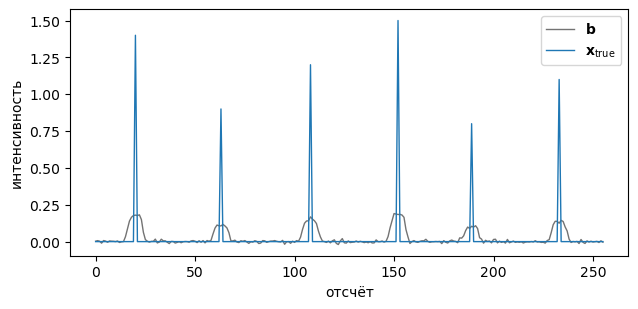

In [ ]:
def flat_top_profile(n, width):
    idx = np.arange(n)
    K = np.exp(-((np.abs(idx[:, None] - idx[None, :]) / width) ** 4))
    K /= K.sum(axis=1, keepdims=True)
    return K

def make_spectrum(n=256, width=4.3, noise=0.008, lam_factor=0.15, seed=1):
    rng = np.random.default_rng(seed)
    K = flat_top_profile(n, width)
    positions = np.array([20, 63, 108, 152, 189, 233])
    amplitudes = np.array([1.4, 0.9, 1.2, 1.5, 0.8, 1.1])
    x_true = np.zeros(n)
    x_true[positions] = amplitudes
    b = K @ x_true + noise * rng.normal(size=n)
    singular = np.linalg.svd(K, compute_uv=False)
    L = float(singular[0] ** 2)
    lam = lam_factor * float(np.max(np.abs(K.T @ b)))
    return K, b, x_true, positions, L, lam

K, b, x_true, positions, L, lam = make_spectrum()

fig, ax = plt.subplots(figsize=(7.2, 3.2))
idx = np.arange(len(b))
ax.plot(idx, b, color="0.45", lw=1, label=r"$\mathbf{b}$")
ax.plot(idx, x_true, color="C0", lw=1, label=r"$\mathbf{x}_{\mathrm{true}}$")
ax.set_xlabel("отсчёт")
ax.set_ylabel("интенсивность")
ax.legend()

Ищется минимум композитной функции

$$
F(\mathbf{x})
=
\frac12\|\mathbf{K}\mathbf{x}-\mathbf{b}\|^2
+
\lambda\sum_{i=1}^{n} x_i,
\qquad \text{при} \qquad
\mathbf{x}\ge\mathbf{0}.
$$


1. **(2 pts)** Определите как лучше разбить функцию на гладкую и негладкую компоненту? Чему равна константа $L$ (Липшицевости градиента) у гладкой компоненты?

Выведите $\operatorname{prox}_{\alpha g}(v)$ с помощью условий оптимальности для выбранной негладкой компоненты $g$ и реализуйте `prox_g(v, alpha, lam)`.


2. **(3 pts)** Реализуйте проксимальный градиентный метод и ускоренную схему с $t_k$ со слайда. Напомним константы: $t_0=1$, $\mathbf{y}_0=\mathbf{x}_0$, $\alpha=1/L$,

$$
\begin{aligned}
\mathbf{x}_{k+1}
&=
\operatorname{prox}_{\alpha g}\bigl(\mathbf{y}_k-\alpha f'(\mathbf{y}_k)\bigr),\\
t_{k+1}
&=
\frac{1+\sqrt{1+4t_k^2}}{2},\\
\mathbf{y}_{k+1}
&=
\mathbf{x}_{k+1}
+
\frac{t_k-1}{t_{k+1}}(\mathbf{x}_{k+1}-\mathbf{x}_k).
\end{aligned}
$$

   

Данные генерируются функцией `make_spectrum()`. Бюджет — 1200 итераций. На одном графике с логарифмической осью $y$ покажите $F(\mathbf{x}_k)-F^\star$ для обоих методов. Возьмите $F^*$ как наименьшее значение целевой функции, которое выдаёт ускоренный проксимальный градиентный метод.

   На рисунке сравните $\mathbf{x}_{\mathrm{true}}$ и решение ускоренного метода. На следующем рисунке сравните $\mathbf{b}$ и $\mathbf{K}\mathbf{x}$ этого решения.

   В комментарии укажите: монотонна ли $F$ вдоль каждой траектории; почему найденные высоты меньше истинных; получается ли восстановить ровно 6 линий как было в исходных данных? Объясните, почему на графике зазора нет прямой линейной фазы, которая у LASSO наблюдается.

3. **(2 pts)** Решите гладкую задачу $\tfrac12\|\mathbf{K}\mathbf{x}-\mathbf{b}\|^2$ методом наименьших квадратов, `numpy.linalg.lstsq(K, b, rcond=None)`. Приведите $\|\mathbf{x}_{\mathrm{ls}}\|_\infty$ и невязку $\|\mathbf{K}\mathbf{x}_{\mathrm{ls}}-\mathbf{b}\|$.
В комментарии объясните, почему маленькая невязка в этой задаче не означает, что вещества найдены, и зачем смеси негладкое слагаемое, хотя проксимальный шаг использует градиент только от $f$.


In [ ]:
def smooth_value(x, K, b):
    r = K @ x - b
    return 0.5 * float(r @ r)


def composite_value(x, K, b, lam):
    return smooth_value(x, K, b) + lam * float(np.sum(x))


def prox_g(v, alpha, lam):
    raise NotImplementedError


## Задача 2 (12 pts). Таблица с пропусками

Сервис хранит таблицу оценок: строки — клиенты, столбцы — товары. Большая часть пар не наблюдалась. Оценки складываются из немногих скрытых факторов, поэтому таблица приблизительно малого ранга. Нужно восстановить пропущенные числа.

Наблюдения — множество пар $\Omega$. По ним строится гладкая функция ошибки

$$
f(\mathbf{X})
=
\frac12
\sum_{(i,j)\in\Omega}
\bigl(X_{ij}-M_{ij}\bigr)^2.
$$

Малый ранг кодируется не рангом, а выпуклым компактом — шаром в ядерной норме

$$
Q
=
\{\mathbf{X}:\|\mathbf{X}\|_*\le\tau\}.
$$

Ядерная норма — сумма сингулярных чисел. Бюджет $\tau$ в коде равен ядерной норме скрытой таблицы, поэтому сама таблица допустима и $f$ на ней равно нулю. Шума нет, значит $f^\star=0$, и значение $f(\mathbf{X}_k)$ уже есть зазор.

- (1 pts) Получите аналитически константу Липшица градиента $f$ 

- (2 pts) Получите аналитически формулы необходимые для подсчёта проекции на множество $Q$ и запишите реализацию этих формул на Python

- (2 pts) Получите необходимые формулы и реализуйте алгоритм вычисления решения задачи LMO для множества $Q$.

Зазор Франк — Вульфа считается как:

$$
f(\mathbf{X})-f^\star
\le
\langle f'(\mathbf{X}),\mathbf{X}-\mathbf{S}\rangle
=
\langle f'(\mathbf{X}),\mathbf{X}\rangle
+
\tau\,\sigma_{\max}\bigl(f'(\mathbf{X})\bigr).
$$

Маска $\Omega_{\mathrm{test}}$ в $f$ не входит. По ней, уже после остановки, считают ошибку прогноза тех оценок, которые метод не видел:

$$
\mathrm{RMSE}
=
\sqrt{
\frac{1}{|\Omega_{\mathrm{test}}|}
\sum_{(i,j)\in\Omega_{\mathrm{test}}}
\bigl(X_{ij}-M_{ij}\bigr)^2
}.
$$


- (3 pts) Вызовите `make_ratings()`: таблица $160\times 200$, четыре скрытых фактора, доля $\Omega$ равна $0{,}2$, доля $\Omega_{\mathrm{test}}$ равна $0{,}05$, `seed=0`. Из нулевой матрицы запустите три метода.

   - Франк — Вульф, $\gamma_k=2/(k+2)$, 400 итераций. В линейной минимизации 15 шагов степенного метода, правый вектор с прошлой итерации передавайте в следующую.
   - Проекция градиента, 20 итераций.
   - Ускоренная проекция со схемой $t_k$, 20 итераций.

   На одном графике с логарифмической осью $y$ изобразите $f(\mathbf{X}_k)$ против номера итерации. Кривые разной длины здесь содержательны: это не повод обрывать метод Франк — Вульфа на 20-й итерации. На втором таком же графике по горизонтали — секунды от старта метода, используйте `time.perf_counter` вокруг цикла вместе с оракулом и без построения графиков.

   В таблице: секунды, финальное $f$, RMSE на $\Omega_{\mathrm{test}}$, сертификат. Для метода Франк — Вульфа сертификат — зазор $\langle f',\mathbf{X}-\mathbf{S}\rangle$ на последней точке. Для двух проекционных методов — норма градиентного отображения:

$$
\mathbf{G}_1(\mathbf{X})
=
\mathbf{X}
-
\Pi_Q\bigl(\mathbf{X}-f'(\mathbf{X})\bigr),
$$

   в норме Фробениуса. Отображение считайте в возвращённой точке $\mathbf{X}$, не в точке упреждения.

   В комментарии отметьте убывает ли $f$ на каждом шаге каждого метода; какой метод сильнее уменьшает $f$ за одну итерацию и какой оказывается ближе к нулю за потраченное время; как RMSE на невидимых оценках согласуется с $f$. Почему гарантия $1/k^2$ у ускоренной проекции не отменяет метод Франк—Вульфа на ядерном шаре.

- (4 pts) Замерьте один вызов линейной минимизации и один вызов проекции на случайных матрицах $80\times 100$ и $240\times 300$. Степенной метод — 15 итераций, без тёплого старта, $\tau=1$. Повторите каждый вызов пять раз и усредните. Перед серией сделайте один прогревочный вызов, его в среднее не включайте.

   В комментарии укажите во сколько раз проекция дороже на каждом размере. Затем проведите аналогичный эксперимент для множества со слайда: спектроэдр $\{\mathbf{X}\succeq 0,\ \mathrm{tr}\,\mathbf{X}=1\}$,  рассмотрите различные размеры матрицы $\mathbf{X}$. Объясните его результаты.


In [ ]:
def make_ratings(m=160, n=200, rank=4, p_train=0.2, p_test=0.05, seed=0):
    rng = np.random.default_rng(seed)
    hidden = rng.normal(size=(m, rank)) @ rng.normal(size=(rank, n)) / np.sqrt(rank)
    tau = float(np.sum(np.linalg.svd(hidden, compute_uv=False)))
    coins = rng.random((m, n))
    train = coins < p_train
    test = (coins >= p_train) & (coins < p_train + p_test)
    observed = np.where(train, hidden, 0.0)
    return hidden, observed, train, test, tau


def observed_value(X, observed, train):
    residual = train * X - observed
    return 0.5 * float(np.sum(residual * residual))


def observed_grad(X, observed, train):
    return train * X - observed

